# YES BANK Stock Price Prediction Using Machine Learning

## 1. Introduction

This project focuses on predicting the next month's closing stock price of YES BANK using historical stock market data and Machine Learning techniques.

The dataset contains historical monthly stock information, including Opening Price, Highest Price, Lowest Price and Closing Price.

Different regression algorithms will be implemented, trained and evaluated to identify a suitable model for predicting future closing prices.

## 2. Problem Statement

To develop a Machine Learning model that predicts the next month's closing price of YES BANK based on historical stock price information.

## 3. Objectives

- Analyse and prepare historical stock price data.
- Perform feature engineering using previous months' stock prices.
- Implement multiple Machine Learning regression algorithms.
- Evaluate model performance using appropriate evaluation metrics.
- Compare models and identify the most suitable prediction model.

## Connection Between EDA and Machine Learning

The Exploratory Data Analysis helped us understand YES BANK's historical closing prices, monthly returns, volatility and price relationships. Based on these observations, Machine Learning models were developed to predict the next month's closing price using historical stock price features.

The EDA phase provided a foundation for feature selection and model development, while the Machine Learning phase evaluated different algorithms to identify a suitable prediction model.

In [60]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Machine Learning libraries
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display settings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [61]:

# Upload the YES BANK dataset

from google.colab import files

uploaded = files.upload()


Saving data_YesBank_StockPrices.csv to data_YesBank_StockPrices (1).csv


In [62]:

# Load the dataset

df = pd.read_csv('data_YesBank_StockPrices.csv')

# Display first five rows
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display dataset information
df.info()


,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41


Dataset Shape: (185, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB


In [63]:

# Convert Date column into datetime format

df['Date'] = pd.to_datetime(df['Date'], format='%b-%y')

# Sort dataset chronologically
df = df.sort_values(by='Date').reset_index(drop=True)

# Display updated data types
print("Updated Data Types:")
print(df.dtypes)

# Display first and last five records
print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())


Updated Data Types:
Date     datetime64[ns]
Open            float64
High            float64
Low             float64
Close           float64
dtype: object

First 5 Records:


,Date,Open,High,Low,Close
0,2005-07-01,13.00,14.00,11.25,12.46
1,2005-08-01,12.58,14.88,12.55,13.42
2,2005-09-01,13.48,14.87,12.27,13.30
3,2005-10-01,13.20,14.47,12.40,12.99
4,2005-11-01,13.35,13.88,12.88,13.41



Last 5 Records:


,Date,Open,High,Low,Close
180,2020-07-01,25.60,28.30,11.10,11.95
181,2020-08-01,12.00,17.16,11.85,14.37
182,2020-09-01,14.30,15.34,12.75,13.15
183,2020-10-01,13.30,14.01,12.11,12.42
184,2020-11-01,12.41,14.90,12.21,14.67


In [64]:

# Feature Engineering

# Previous month's closing price
df['Close_Lag_1'] = df['Close'].shift(1)

# Closing prices from previous two and three months
df['Close_Lag_2'] = df['Close'].shift(2)
df['Close_Lag_3'] = df['Close'].shift(3)

# Previous month's return
df['Previous_Month_Return'] = df['Close'].pct_change() * 100

# Moving averages using only historical information
df['MA_3'] = df['Close'].rolling(window=3).mean()
df['MA_6'] = df['Close'].rolling(window=6).mean()

# Display the engineered features
display(df[['Date', 'Close', 'Close_Lag_1',
            'Close_Lag_2', 'Close_Lag_3',
            'Previous_Month_Return', 'MA_3', 'MA_6']].head(10))


,Date,Close,Close_Lag_1,Close_Lag_2,Close_Lag_3,Previous_Month_Return,MA_3,MA_6
0,2005-07-01,12.46,NaN,NaN,NaN,NaN,NaN,NaN
1,2005-08-01,13.42,12.46,NaN,NaN,7.704655,NaN,NaN
2,2005-09-01,13.30,13.42,12.46,NaN,-0.894188,13.060000,NaN
3,2005-10-01,12.99,13.30,13.42,12.46,-2.330827,13.236667,NaN
4,2005-11-01,13.41,12.99,13.30,13.42,3.233256,13.233333,NaN
5,2005-12-01,13.71,13.41,12.99,13.30,2.237136,13.370000,13.215000
6,2006-01-01,15.33,13.71,13.41,12.99,11.816193,14.150000,13.693333
7,2006-02-01,16.12,15.33,13.71,13.41,5.153294,15.053333,14.143333
8,2006-03-01,20.08,16.12,15.33,13.71,24.565757,17.176667,15.273333
9,2006-04-01,19.49,20.08,16.12,15.33,-2.938247,18.563333,16.356667


In [65]:

# Create target variable: Next month's closing price

df['Next_Month_Close'] = df['Close'].shift(-1)

# Display current closing price and next month's target
display(df[['Date', 'Close', 'Next_Month_Close']].head(10))

print("Original Dataset Shape:", df.shape)


,Date,Close,Next_Month_Close
0,2005-07-01,12.46,13.42
1,2005-08-01,13.42,13.30
2,2005-09-01,13.30,12.99
3,2005-10-01,12.99,13.41
4,2005-11-01,13.41,13.71
5,2005-12-01,13.71,15.33
6,2006-01-01,15.33,16.12
7,2006-02-01,16.12,20.08
8,2006-03-01,20.08,19.49
9,2006-04-01,19.49,18.03


Original Dataset Shape: (185, 12)


In [66]:
# Select input features

features = [
    'Open',
    'High',
    'Low',
    'Close',
    'Close_Lag_1',
    'Close_Lag_2',
    'Close_Lag_3',
    'Previous_Month_Return',
    'MA_3',
    'MA_6'
]

# Create final modelling dataset
ml_df = df[features + ['Next_Month_Close']].copy()

# Remove rows with missing values
ml_df.dropna(inplace=True)

# Reset index
ml_df.reset_index(drop=True, inplace=True)

print("Final Dataset Shape:", ml_df.shape)
display(ml_df.head())

Final Dataset Shape: (179, 11)


,Open,High,Low,Close,Close_Lag_1,Close_Lag_2,Close_Lag_3,Previous_Month_Return,MA_3,MA_6,Next_Month_Close
0,13.49,14.44,13.00,13.71,13.41,12.99,13.30,2.237136,13.370000,13.215000,15.33
1,13.68,17.16,13.58,15.33,13.71,13.41,12.99,11.816193,14.150000,13.693333,16.12
2,15.50,16.97,15.40,16.12,15.33,13.71,13.41,5.153294,15.053333,14.143333,20.08
3,16.20,20.95,16.02,20.08,16.12,15.33,13.71,24.565757,17.176667,15.273333,19.49
4,20.56,20.80,18.02,19.49,20.08,16.12,15.33,-2.938247,18.563333,16.356667,18.03


In [67]:
# Independent variables and target variable

X = ml_df[features]
y = ml_df['Next_Month_Close']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (179, 10)
Target Shape: (179,)


In [68]:
# Chronological train-test split

split_index = int(len(ml_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

# Correct date alignment for training and testing periods

valid_indices = df[
    features + ['Next_Month_Close']
].dropna().index

feature_dates = df.loc[
    valid_indices, 'Date'
].reset_index(drop=True)

target_dates = df.loc[
    valid_indices + 1, 'Date'
].reset_index(drop=True)

print("Training Feature Period:",
      feature_dates.iloc[0], "to",
      feature_dates.iloc[split_index - 1])

print("Training Target Period:",
      target_dates.iloc[0], "to",
      target_dates.iloc[split_index - 1])

print("Testing Target Period:",
      target_dates.iloc[split_index], "to",
      target_dates.iloc[-1])

Training Records: 143
Testing Records: 36
Training Feature Period: 2005-12-01 00:00:00 to 2017-10-01 00:00:00
Training Target Period: 2006-01-01 00:00:00 to 2017-11-01 00:00:00
Testing Target Period: 2017-12-01 00:00:00 to 2020-11-01 00:00:00


In [69]:
# Naive baseline prediction

baseline_predictions = X_test['Close'].values

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL PERFORMANCE")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R2 Score:", round(baseline_r2, 4))

BASELINE MODEL PERFORMANCE
MAE: 23.8
RMSE: 38.82
R2 Score: 0.9072


In [70]:
# Linear Regression Model

linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict the test data
lr_predictions = linear_model.predict(X_test)

print("Linear Regression Model trained successfully!")
print("First 10 Predictions:")
print(lr_predictions[:10])

Linear Regression Model trained successfully!
First 10 Predictions:
[323.48174844 337.96923996 364.40069648 324.6504017  316.72656163
 370.83620946 353.42710543 353.25274245 373.05744129 343.82436604]


In [71]:
# Decision Tree Regressor

dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict the test data
dt_predictions = dt_model.predict(X_test)

print("Decision Tree Model trained successfully!")
print("First 10 Predictions:")
print(dt_predictions[:10])

Decision Tree Model trained successfully!
First 10 Predictions:
[306.8  361.96 350.   350.   314.35 350.   350.   314.35 306.8  306.8 ]


In [72]:
# Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict the test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest Model trained successfully!")
print("First 10 Predictions:")
print(rf_predictions[:10])

Random Forest Model trained successfully!
First 10 Predictions:
[326.7293 330.6105 336.4825 321.2082 328.0741 336.0614 328.993  322.9444
 327.7157 322.7622]


In [73]:
# Support Vector Regression

svr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR(kernel='rbf', C=100, epsilon=0.1))
])

# Train the model
svr_model.fit(X_train, y_train)

# Predict the test data
svr_predictions = svr_model.predict(X_test)

print("SVR Model trained successfully!")
print("First 10 Predictions:")
print(svr_predictions[:10])

SVR Model trained successfully!
First 10 Predictions:
[322.77011937 336.02285997 349.36830516 315.95124842 315.41521604
 334.99166071 325.43636599 319.8026528  324.66752375 307.3609035 ]


In [74]:
# Model Evaluation

models = {
    'Baseline': baseline_predictions,
    'Linear Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'Random Forest': rf_predictions,
    'SVR': svr_predictions
}

results = []

for model_name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Baseline,23.7964,1507.1192,38.8216,0.9072
1,Linear Regression,26.6172,1597.1141,39.9639,0.9017
2,Decision Tree,27.7378,1527.3048,39.0807,0.9060
3,Random Forest,29.7107,1858.7677,43.1134,0.8855
4,SVR,25.0602,1352.3111,36.7738,0.9167


## Model Performance Visualization

The performance of different regression models is compared using MAE, RMSE and R² Score. These visualizations help identify models with lower prediction errors and better explanatory performance.

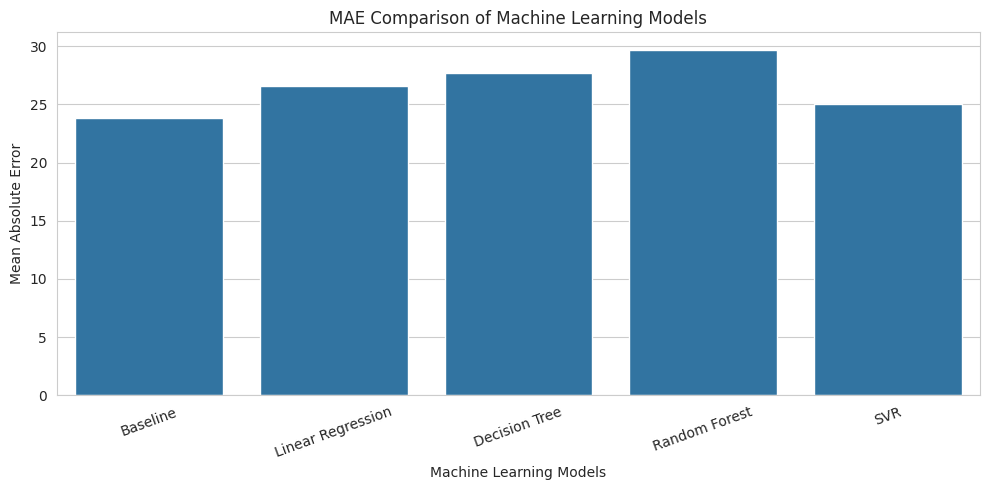

In [75]:
# MAE Comparison

plt.figure(figsize=(10, 5))

sns.barplot(data=results_df, x='Model', y='MAE')

plt.title('MAE Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Interpretation

- Mean Absolute Error (MAE) measures the average absolute difference between actual and predicted closing prices.
- The Baseline model achieved the lowest MAE of 23.7964.
- Among the Machine Learning models, SVR achieved the lowest MAE of 25.0602.
- This indicates that the previous month's closing price provides a strong benchmark for next-month price prediction.

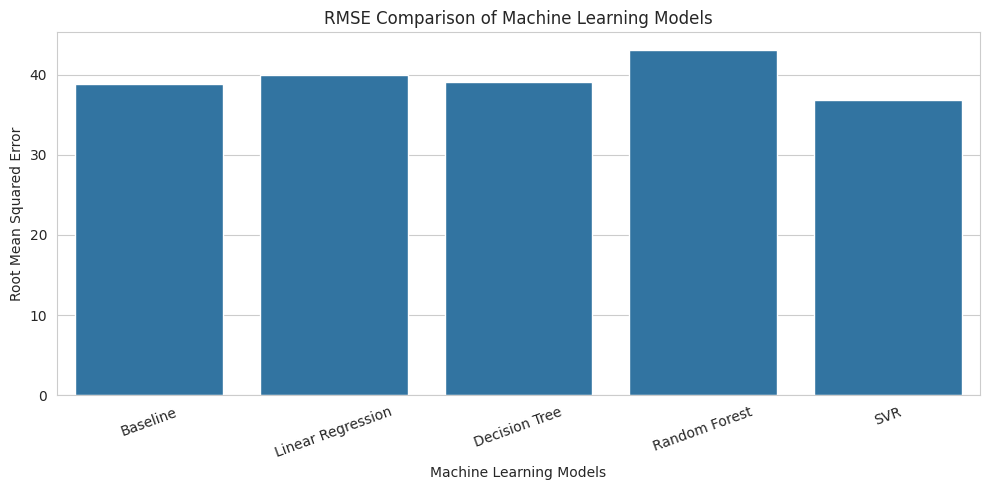

In [76]:
# RMSE Comparison

plt.figure(figsize=(10, 5))

sns.barplot(data=results_df, x='Model', y='RMSE')

plt.title('RMSE Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Root Mean Squared Error')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Interpretation

- Root Mean Squared Error (RMSE) measures prediction errors while giving greater weight to larger errors.
- SVR achieved the lowest RMSE of 36.7738 among all evaluated models.
- This indicates that SVR performed comparatively better in minimizing larger prediction errors on the test dataset.
- The results suggest that SVR captured the stock price patterns effectively in the test period.

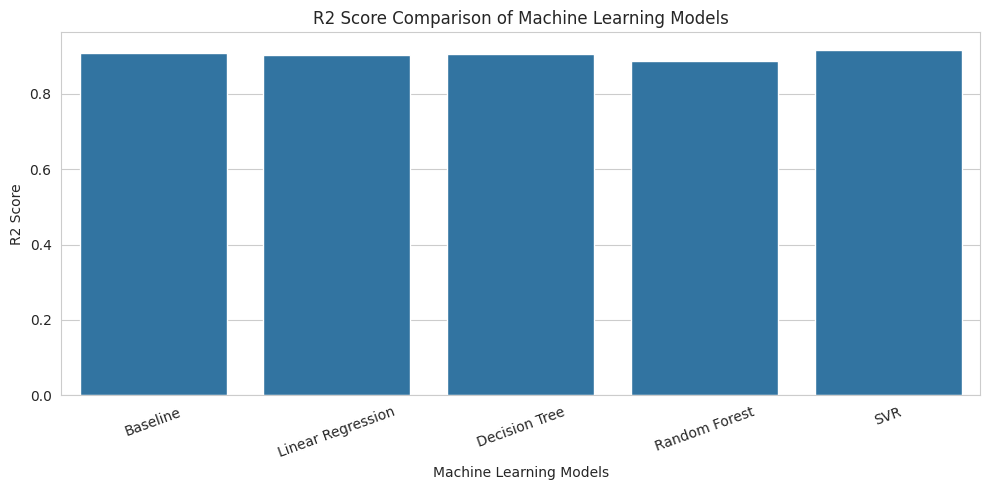

In [77]:
# R2 Score Comparison

plt.figure(figsize=(10, 5))

sns.barplot(data=results_df, x='Model', y='R2 Score')

plt.title('R2 Score Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('R2 Score')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Interpretation

- R² Score indicates how much of the variation in the actual closing prices is explained by the model.
- SVR achieved the highest R² score of 0.9167.
- This means that approximately 91.67% of the variation in the test target values was explained by the SVR model.
- The result indicates a strong fit between the actual and predicted values on the test dataset.

## Time Series Cross-Validation

TimeSeriesSplit is used to evaluate model performance across multiple chronological data splits. This helps assess model stability and reduces the risk of relying on a single train-test split.

In [78]:
# Time Series Cross-Validation

from sklearn.model_selection import cross_val_score

tscv = TimeSeriesSplit(n_splits=5)

cv_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    'SVR': Pipeline([
        ('scaler', StandardScaler()),
        ('svr', SVR(kernel='rbf', C=100, epsilon=0.1))
    ])
}

cv_results = []

# Evaluate Machine Learning models
for name, model in cv_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring='neg_mean_absolute_error'
    )

    cv_results.append({
        'Model': name,
        'Average CV MAE': -scores.mean(),
        'Standard Deviation': scores.std()
    })

# Evaluate the baseline using the same chronological splits
baseline_cv_scores = []

for train_index, val_index in tscv.split(X_train):

    actual = y_train.iloc[val_index]
    predicted = X_train.iloc[val_index]['Close']

    score = mean_absolute_error(actual, predicted)
    baseline_cv_scores.append(score)

cv_results.append({
    'Model': 'Baseline',
    'Average CV MAE': np.mean(baseline_cv_scores),
    'Standard Deviation': np.std(baseline_cv_scores)
})

cv_results_df = pd.DataFrame(cv_results)

print("TIME SERIES CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

TIME SERIES CROSS-VALIDATION RESULTS


,Model,Average CV MAE,Standard Deviation
0,Linear Regression,10.9473,5.4227
1,Decision Tree,43.8838,44.3228
2,Random Forest,40.1672,36.0110
3,SVR,60.4838,56.7957
4,Baseline,9.3301,5.7277


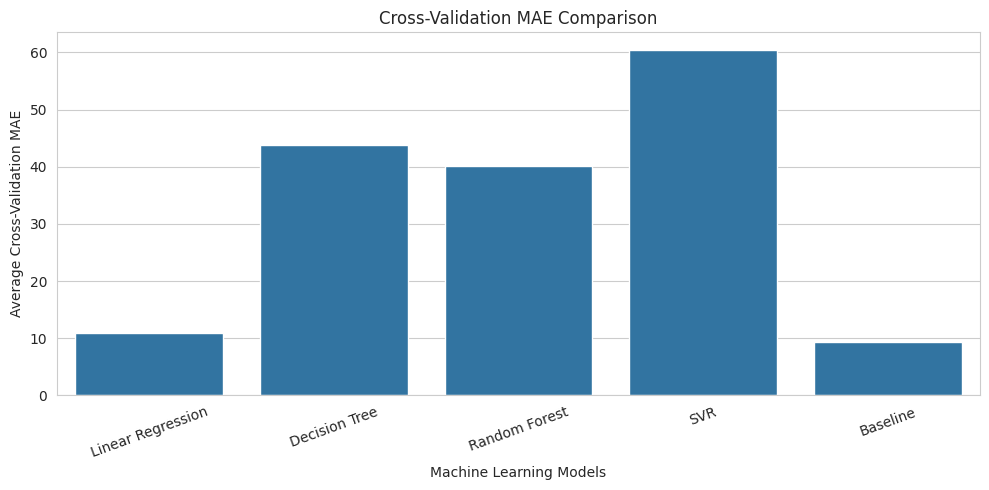

In [79]:
# Cross-Validation Performance Comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results_df,
    x='Model',
    y='Average CV MAE'
)

plt.title('Cross-Validation MAE Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Average Cross-Validation MAE')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Interpretation

- Time-series cross-validation evaluates model performance across multiple chronological validation periods.
- The Baseline model achieved the lowest average CV MAE of 9.3301.
- Linear Regression achieved the lowest average CV MAE of 10.9473 among the Machine Learning models.
- SVR showed a higher average CV MAE of 60.4838, indicating variation in its performance across validation periods.
- These results highlight the importance of checking model consistency across different time periods rather than relying only on a single train-test split.

## Hyperparameter Tuning

Hyperparameter tuning is performed using GridSearchCV to identify suitable model configurations. TimeSeriesSplit is used to maintain the chronological order of the stock price data.

In [80]:
# Decision Tree Hyperparameter Tuning

dt_param_grid = {
    'max_depth': [2, 3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=dt_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

best_dt_model = dt_grid.best_estimator_

print("Best Decision Tree Parameters:")
print(dt_grid.best_params_)

print("Best Cross-Validation MAE:")
print(round(-dt_grid.best_score_, 4))

Best Decision Tree Parameters:
{'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best Cross-Validation MAE:
37.0789


In [81]:
# Random Forest Hyperparameter Tuning

rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf_model = rf_grid.best_estimator_

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best Cross-Validation MAE:")
print(round(-rf_grid.best_score_, 4))

Best Random Forest Parameters:
{'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 50}
Best Cross-Validation MAE:
37.1356


In [82]:
# SVR Hyperparameter Tuning

svr_param_grid = {
    'svr__C': [1, 10, 100, 500],
    'svr__epsilon': [0.1, 0.5, 1],
    'svr__gamma': ['scale', 'auto']
}

svr_grid = GridSearchCV(
    Pipeline([
        ('scaler', StandardScaler()),
        ('svr', SVR(kernel='rbf'))
    ]),
    param_grid=svr_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

svr_grid.fit(X_train, y_train)

best_svr_model = svr_grid.best_estimator_

print("Best SVR Parameters:")
print(svr_grid.best_params_)

print("Best Cross-Validation MAE:")
print(round(-svr_grid.best_score_, 4))

Best SVR Parameters:
{'svr__C': 10, 'svr__epsilon': 0.1, 'svr__gamma': 'scale'}
Best Cross-Validation MAE:
59.548


In [83]:
# Evaluate Tuned Models on Test Data

tuned_models = {
    'Tuned Decision Tree': best_dt_model,
    'Tuned Random Forest': best_rf_model,
    'Tuned SVR': best_svr_model
}

tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    tuned_results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

tuned_results_df = pd.DataFrame(tuned_results)

print("TUNED MODEL PERFORMANCE")
display(tuned_results_df.round(4))

TUNED MODEL PERFORMANCE


,Model,MAE,MSE,RMSE,R2 Score
0,Tuned Decision Tree,27.1799,1509.1062,38.8472,0.9071
1,Tuned Random Forest,32.2552,2108.7042,45.9206,0.8702
2,Tuned SVR,51.9687,5110.4314,71.4873,0.6853


In [84]:
# Complete Model Performance Comparison

all_models = {
    'Baseline': None,
    'Linear Regression': linear_model,
    'Decision Tree': dt_model,
    'Tuned Decision Tree': best_dt_model,
    'Random Forest': rf_model,
    'Tuned Random Forest': best_rf_model,
    'SVR': svr_model,
    'Tuned SVR': best_svr_model
}

comparison_results = []

for name, model in all_models.items():

    if name == 'Baseline':
        predictions = baseline_predictions
    else:
        predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    comparison_results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

final_comparison_df = pd.DataFrame(comparison_results)

print("COMPLETE MODEL PERFORMANCE COMPARISON")
display(
    final_comparison_df
    .sort_values(by='MAE')
    .reset_index(drop=True)
    .round(4)
)

COMPLETE MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Baseline,23.7964,1507.1192,38.8216,0.9072
1,SVR,25.0602,1352.3111,36.7738,0.9167
2,Linear Regression,26.6172,1597.1141,39.9639,0.9017
3,Tuned Decision Tree,27.1799,1509.1062,38.8472,0.9071
4,Decision Tree,27.7378,1527.3048,39.0807,0.9060
5,Random Forest,29.7107,1858.7677,43.1134,0.8855
6,Tuned Random Forest,32.2552,2108.7042,45.9206,0.8702
7,Tuned SVR,51.9687,5110.4314,71.4873,0.6853


In [85]:
# Identify the Model with Lowest MAE

best_model_name = final_comparison_df.loc[
    final_comparison_df['MAE'].idxmin(), 'Model'
]

best_mae = final_comparison_df['MAE'].min()

print("Model with Lowest MAE:", best_model_name)
print("Lowest MAE:", round(best_mae, 4))

Model with Lowest MAE: Baseline
Lowest MAE: 23.7964


## Model Selection and Justification

The baseline model achieved the lowest Mean Absolute Error (MAE), showing that the previous month's closing price is a strong benchmark for predicting the next month's price.

Among the implemented Machine Learning models, Support Vector Regression (SVR) achieved the lowest RMSE and highest R² score on the test dataset.

However, the baseline model also performed better in time-series cross-validation. Therefore, SVR is selected as the final Machine Learning model based on its test RMSE and R² performance, while the baseline remains an important benchmark.

This comparison highlights the importance of evaluating models using multiple performance metrics and validating their consistency across different time periods.

## Actual vs Predicted Stock Prices

This visualization compares the actual next-month closing prices with the predictions generated by the Support Vector Regression model. It helps assess how closely the model follows the actual stock price movement.

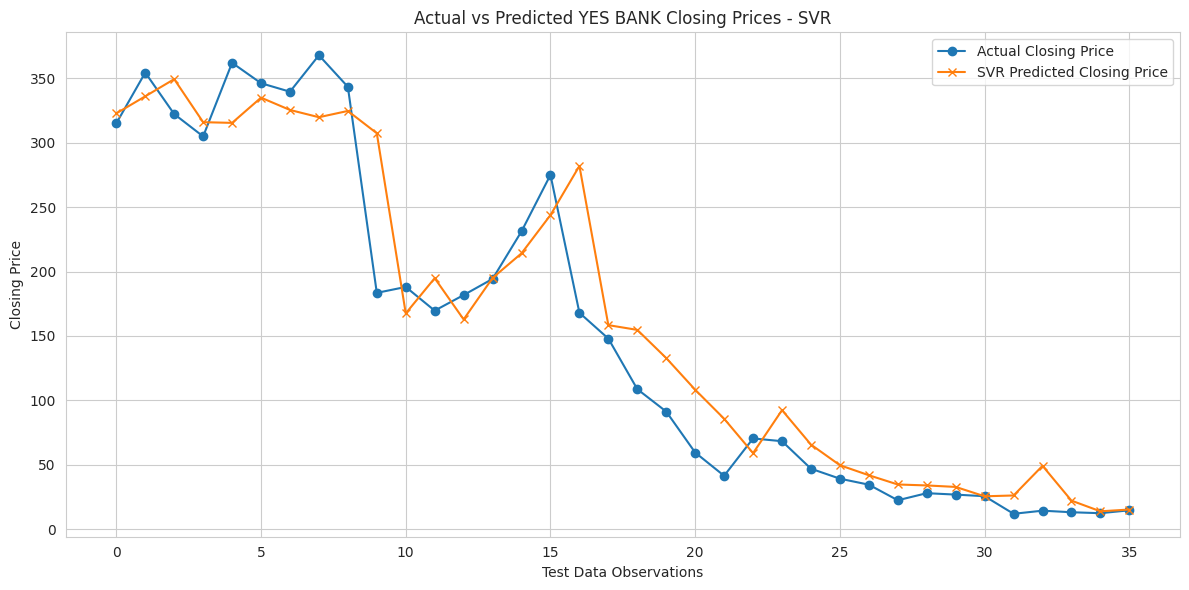

In [86]:
# Actual vs Predicted Prices - SVR

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(y_test)),
    y_test.values,
    label='Actual Closing Price',
    marker='o'
)

plt.plot(
    range(len(svr_predictions)),
    svr_predictions,
    label='SVR Predicted Closing Price',
    marker='x'
)

plt.title('Actual vs Predicted YES BANK Closing Prices - SVR')
plt.xlabel('Test Data Observations')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation

- The chart compares actual next-month closing prices with the values predicted by the SVR model.
- The closeness of the two lines indicates how effectively the model follows the actual stock price movement.
- Differences between the lines represent prediction errors.
- The comparison helps identify how well the SVR model captures price movements in the test dataset.

## Residual Error Distribution

Residual analysis helps understand the distribution of prediction errors. A residual close to zero indicates that the predicted price is close to the actual price.

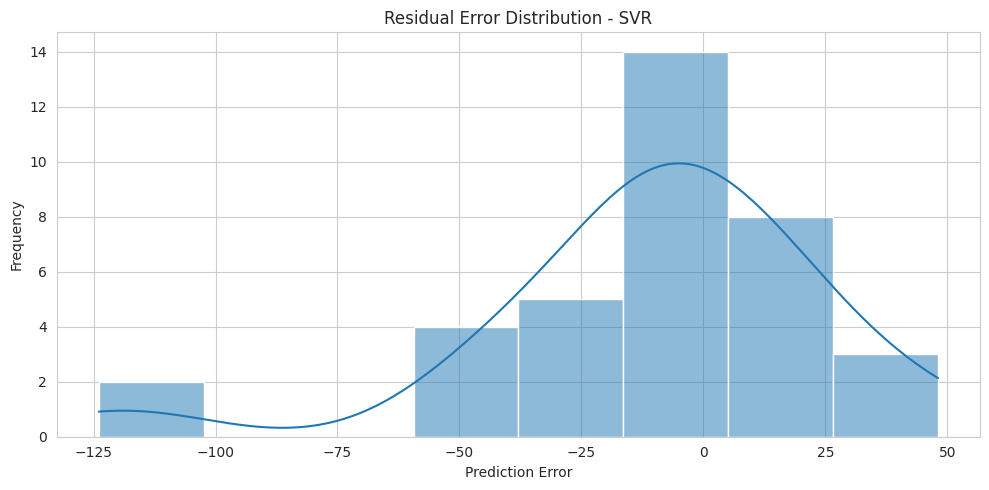

In [87]:
# Residual Error Distribution

svr_residuals = y_test.values - svr_predictions

plt.figure(figsize=(10, 5))

sns.histplot(svr_residuals, kde=True)

plt.title('Residual Error Distribution - SVR')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Interpretation

- Residuals represent the difference between actual and predicted closing prices.
- A residual value close to zero indicates a smaller prediction error.
- The histogram shows how frequently different prediction errors occur.
- The distribution helps identify whether the model's errors are concentrated around zero or spread across a wider range.
- This analysis provides additional insight into the prediction accuracy of the SVR model.

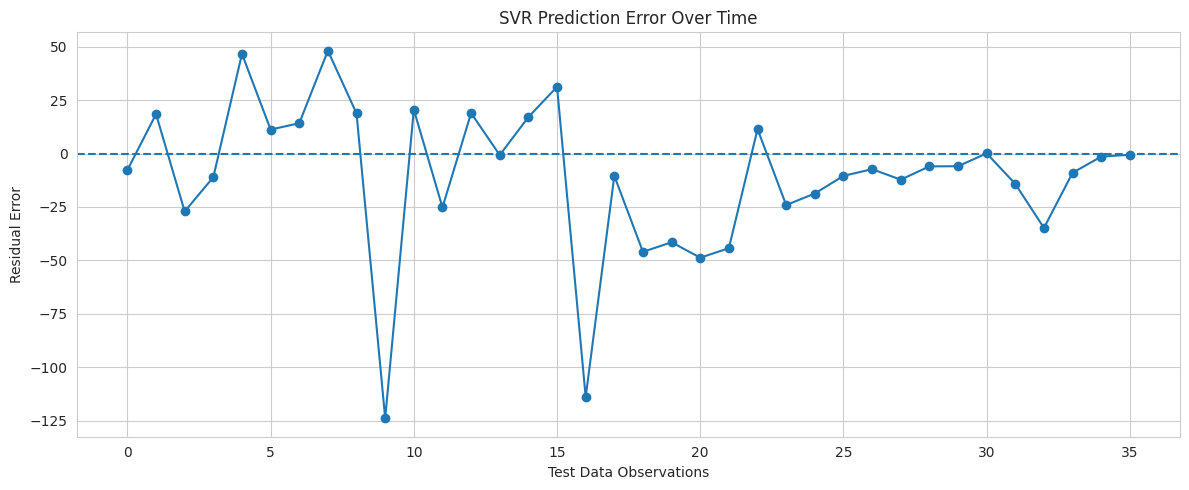

In [88]:
# Prediction Error Over Time

plt.figure(figsize=(12, 5))

plt.plot(
    range(len(svr_residuals)),
    svr_residuals,
    marker='o'
)

plt.axhline(y=0, linestyle='--')

plt.title('SVR Prediction Error Over Time')
plt.xlabel('Test Data Observations')
plt.ylabel('Residual Error')
plt.tight_layout()
plt.show()

### Interpretation

- This chart shows how the SVR model's prediction errors change across the test observations.
- The horizontal zero line represents perfect prediction.
- Positive residuals indicate that the actual closing price was higher than the predicted price.
- Negative residuals indicate that the predicted price was higher than the actual price.
- Variations around the zero line help identify periods where the model produces larger prediction errors.

## Feature Importance Analysis

Feature importance analysis identifies the input variables that contribute most to the predictions made by the Random Forest model. This helps understand which historical stock price indicators are useful for forecasting.

,Feature,Importance
3,Close,0.2548
2,Low,0.1589
1,High,0.1443
9,MA_6,0.1016
4,Close_Lag_1,0.0867
0,Open,0.0703
6,Close_Lag_3,0.0687
8,MA_3,0.0565
5,Close_Lag_2,0.0550
7,Previous_Month_Return,0.0034


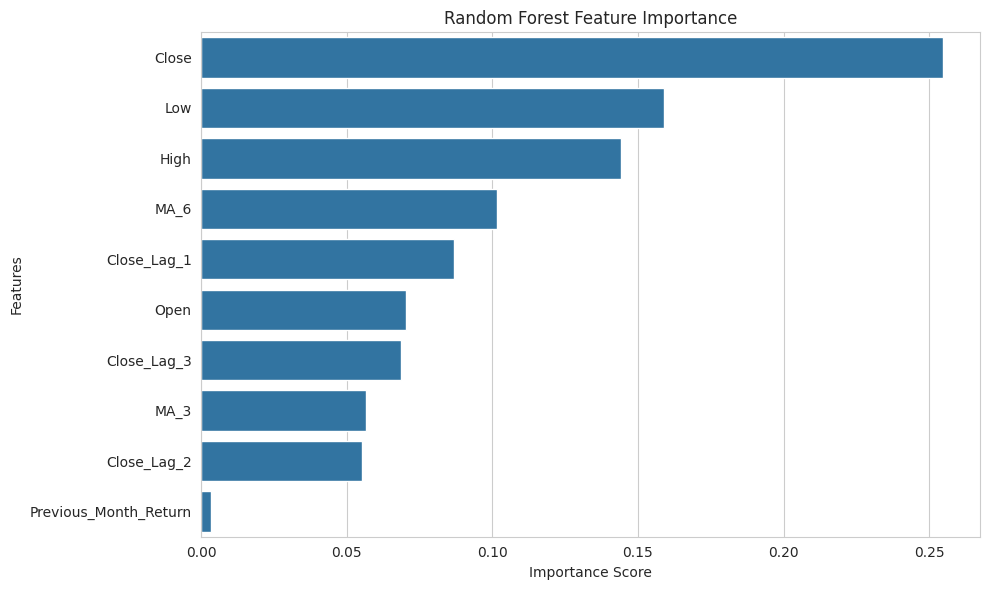

In [89]:
# Random Forest Feature Importance

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Interpretation

- Feature importance identifies the input variables that contribute to the Random Forest model's predictions.
- Features with higher importance scores have a greater influence on the model's predictions.
- Historical closing prices, lag features and moving averages provide information about previous price behaviour.
- This analysis helps understand which historical stock price indicators are useful for predicting the next month's closing price.
- Feature importance indicates the contribution of features within the Random Forest model and does not establish a causal relationship.

## Next-Month Closing Price Distribution

This chart examines the distribution of the target variable used for prediction and helps identify the spread of future closing prices in the prepared dataset.

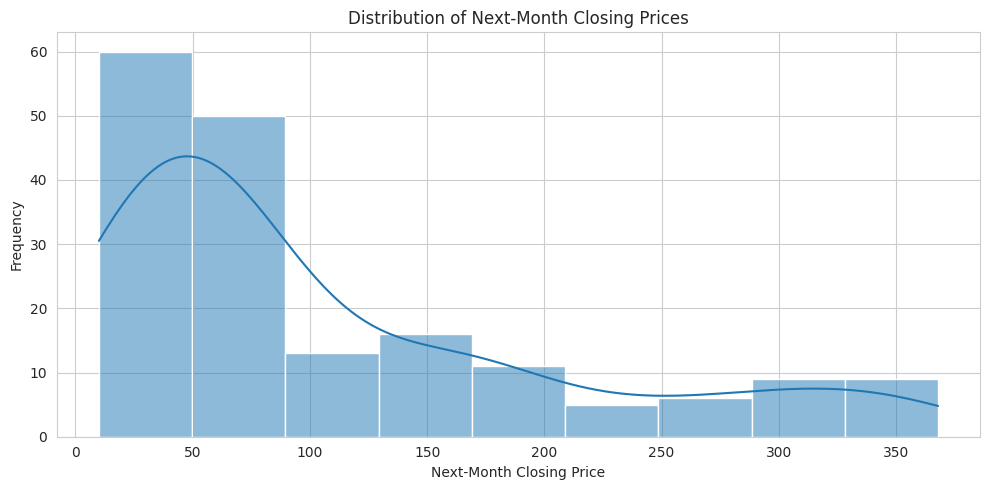

In [90]:
# Target Variable Distribution

plt.figure(figsize=(10, 5))

sns.histplot(y, kde=True)

plt.title('Distribution of Next-Month Closing Prices')
plt.xlabel('Next-Month Closing Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Interpretation

- The histogram represents the distribution of next-month closing prices used as the target variable.
- It shows the frequency of different closing price ranges in the prepared dataset.
- The distribution helps understand the variation and spread of the target values.
- This analysis provides an overview of the price ranges the Machine Learning models are trained to predict.

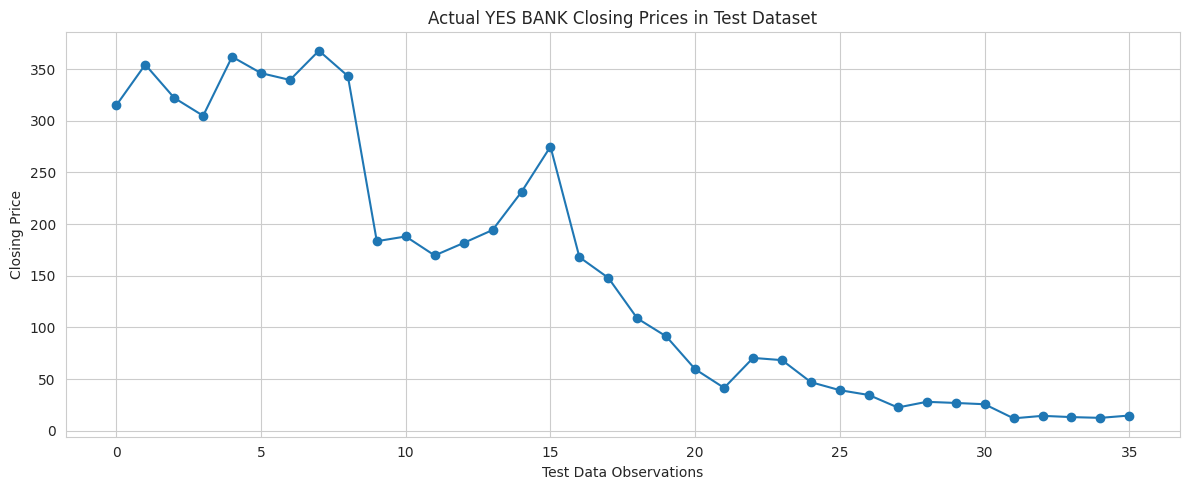

In [91]:
# Actual Test Closing Price Trend

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, marker='o')

plt.title('Actual YES BANK Closing Prices in Test Dataset')
plt.xlabel('Test Data Observations')
plt.ylabel('Closing Price')
plt.tight_layout()
plt.show()

### Interpretation

- This chart displays the actual YES BANK closing prices in the test dataset.
- It highlights the changes and fluctuations in stock prices during the testing period.
- The visualization provides a reference for comparing the predictions generated by different models.
- It also helps understand the price movements that the models were expected to forecast.

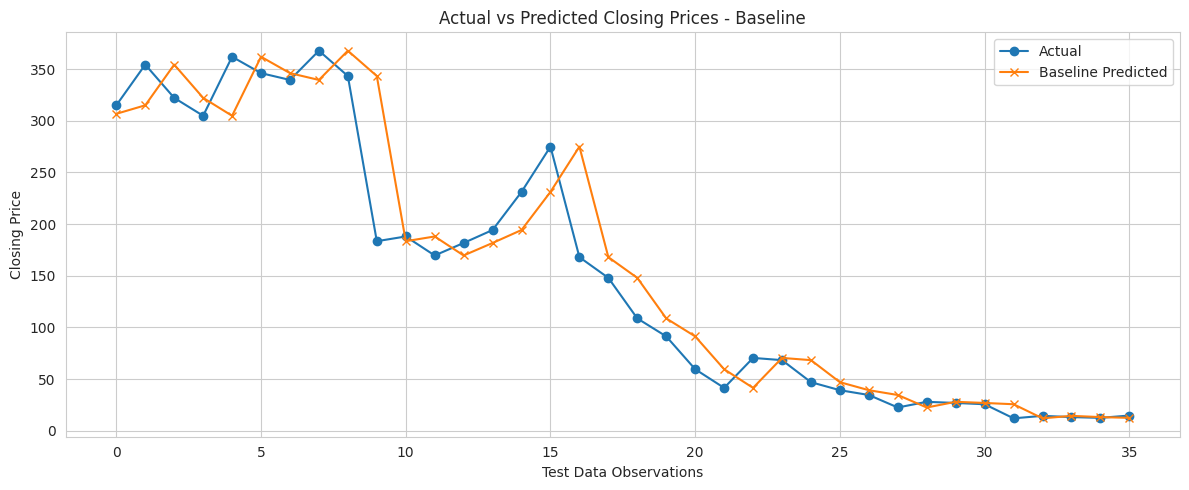

In [92]:
# Baseline Actual vs Predicted

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label='Actual', marker='o')
plt.plot(baseline_predictions, label='Baseline Predicted', marker='x')

plt.title('Actual vs Predicted Closing Prices - Baseline')
plt.xlabel('Test Data Observations')
plt.ylabel('Closing Price')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

- The chart compares actual closing prices with the predictions from the baseline model.
- The baseline uses the previous month's closing price as the prediction for the next month.
- The predicted values follow the previous month's price behaviour, providing a simple benchmark for evaluating Machine Learning models.
- The baseline achieved the lowest MAE of 23.7964 in the original test comparison.

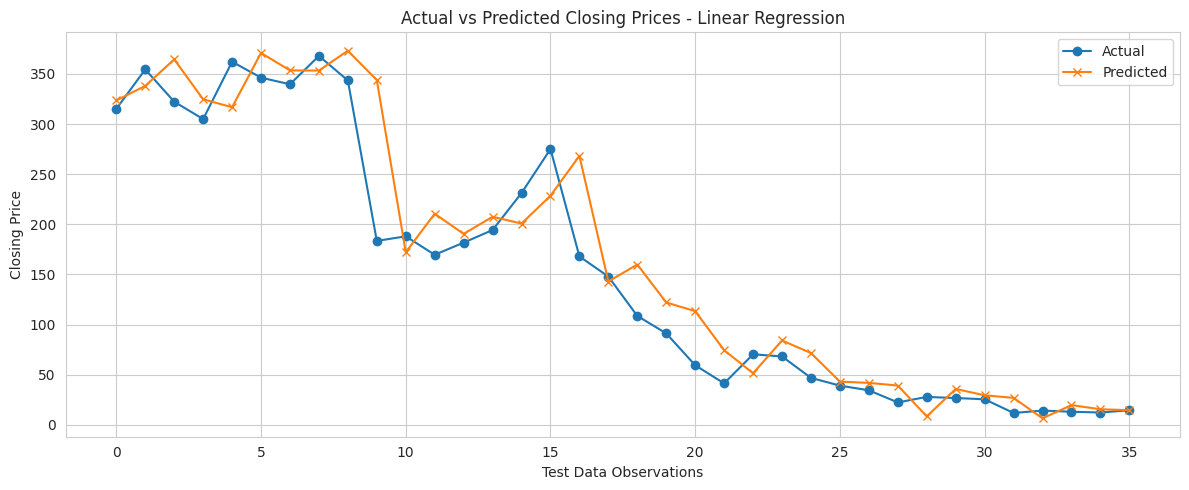

In [93]:
# Linear Regression Actual vs Predicted

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label='Actual', marker='o')
plt.plot(lr_predictions, label='Predicted', marker='x')

plt.title('Actual vs Predicted Closing Prices - Linear Regression')
plt.xlabel('Test Data Observations')
plt.ylabel('Closing Price')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

- This chart compares the actual closing prices with the values predicted by Linear Regression.
- The model attempts to learn the relationship between historical stock price features and next-month closing prices.
- Differences between the actual and predicted lines indicate the model's prediction errors.
- The visualization helps assess how closely the Linear Regression model follows the actual price movements.

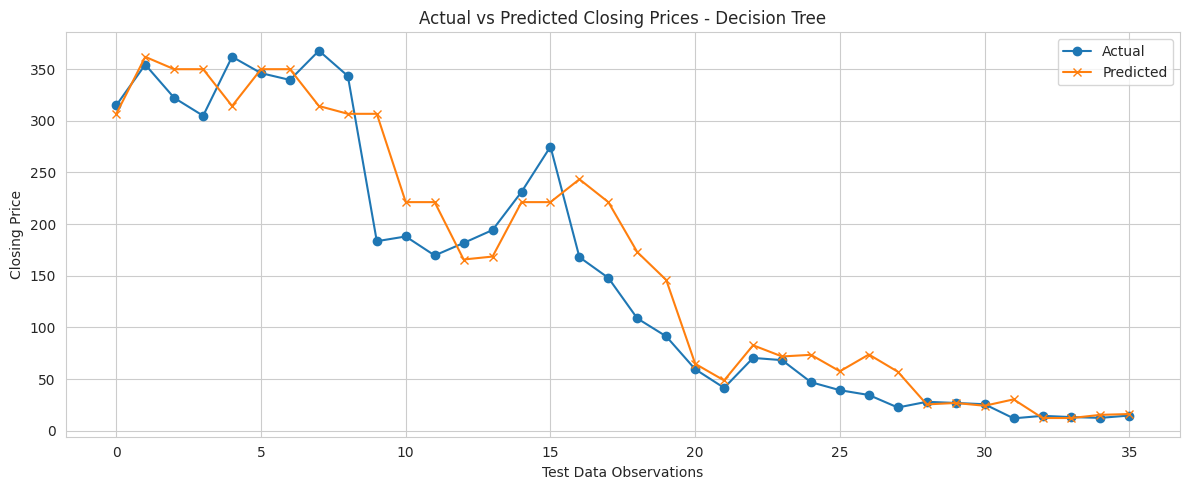

In [94]:
# Decision Tree Actual vs Predicted

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label='Actual', marker='o')
plt.plot(dt_predictions, label='Predicted', marker='x')

plt.title('Actual vs Predicted Closing Prices - Decision Tree')
plt.xlabel('Test Data Observations')
plt.ylabel('Closing Price')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

- This chart compares actual closing prices with the predictions generated by the Decision Tree model.
- The model uses decision-based splits to identify patterns in the historical stock price features.
- The distance between the actual and predicted lines represents prediction errors.
- The visualization helps evaluate the model's ability to capture changes in stock prices.

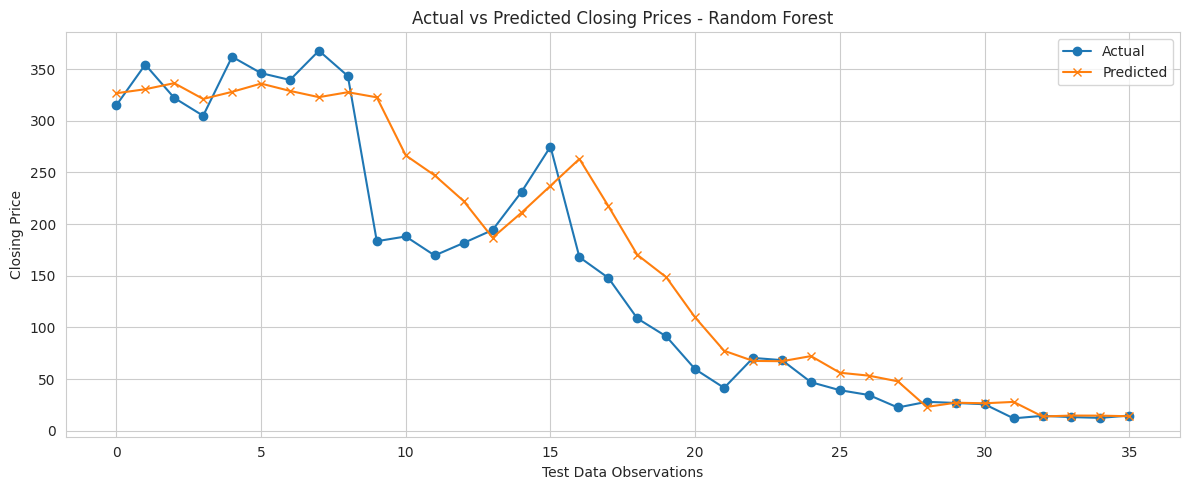

In [95]:
# Random Forest Actual vs Predicted

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label='Actual', marker='o')
plt.plot(rf_predictions, label='Predicted', marker='x')

plt.title('Actual vs Predicted Closing Prices - Random Forest')
plt.xlabel('Test Data Observations')
plt.ylabel('Closing Price')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

- This chart compares actual closing prices with the predictions generated by the Random Forest model.
- Random Forest combines predictions from multiple decision trees to produce the final output.
- The closeness of the actual and predicted lines indicates the model's forecasting performance.
- The visualization helps identify how effectively the model follows stock price movements during the test period.

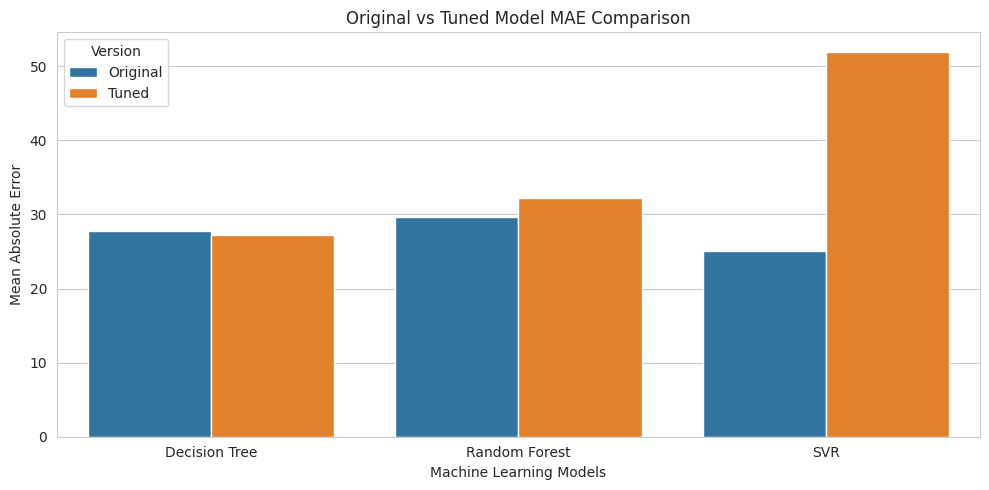

In [96]:
# Original vs Tuned Model MAE Comparison

tuning_comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Decision Tree',
        'Random Forest',
        'Random Forest',
        'SVR',
        'SVR'
    ],
    'Version': [
        'Original', 'Tuned',
        'Original', 'Tuned',
        'Original', 'Tuned'
    ],
    'MAE': [
        27.7378, 27.1799,
        29.7107, 32.2552,
        25.0602, 51.9687
    ]
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuning_comparison,
    x='Model',
    y='MAE',
    hue='Version'
)

plt.title('Original vs Tuned Model MAE Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Mean Absolute Error')
plt.tight_layout()
plt.show()

### Interpretation

- This chart compares the MAE of the original and hyperparameter-tuned Decision Tree, Random Forest and SVR models.
- The tuned Decision Tree showed a slight improvement, with its MAE decreasing from 27.7378 to 27.1799.
- The tuned Random Forest MAE increased from 29.7107 to 32.2552.
- The tuned SVR MAE increased from 25.0602 to 51.9687.
- These results show that hyperparameter tuning does not always improve test performance.
- Model performance should therefore be evaluated using actual test results rather than assuming that tuning will always produce better predictions.

## Business Insights

1. Historical closing prices show considerable variation, indicating fluctuations in YES BANK's stock market performance.

2. Monthly stock returns and rolling volatility highlight periods of significant price movements and market uncertainty.

3. The baseline model achieved the lowest MAE of 23.7964, showing that the previous month's closing price is a strong benchmark for next-month predictions.

4. Among the implemented Machine Learning models, SVR achieved the lowest RMSE of 36.7738 and the highest R² score of 0.9167 on the test dataset.

5. Hyperparameter tuning did not improve the test performance of every model, demonstrating that model complexity does not always result in better predictions.

6. Time-series cross-validation showed that model performance varies across historical periods, highlighting the importance of evaluating forecasting models on chronological data.

## Limitations

1. The dataset contains only 185 monthly observations, which limits the amount of historical information available for model training.

2. The dataset contains only OHLC stock price information and does not include external factors such as company financial performance, market news, economic indicators or investor sentiment.

3. Stock prices are influenced by unpredictable market events, making accurate long-term forecasting challenging.

4. The model's performance may vary across different market conditions.

5. The predictions are based on historical patterns and should not be considered financial or investment advice.

## Conclusion

This project developed and evaluated multiple Machine Learning regression models to predict the next month's YES BANK closing stock price using historical stock market data.

Linear Regression, Decision Tree, Random Forest and Support Vector Regression were implemented and evaluated using MAE, MSE, RMSE and R² score.

Among the implemented Machine Learning models, Support Vector Regression achieved the best RMSE of 36.7738 and R² score of 0.9167 on the test dataset. However, the baseline model achieved a lower MAE of 23.7964 and performed best in time-series cross-validation.

The project demonstrates the importance of feature engineering, chronological data splitting, model evaluation, cross-validation and hyperparameter tuning in developing stock price forecasting models.

Overall, the results highlight both the potential and limitations of using historical stock price data for predicting future market movements.

In [97]:
# Save the Selected SVR Model

import joblib

joblib.dump(svr_model, 'yes_bank_svr_model.pkl')

joblib.dump(features, 'yes_bank_features.pkl')

print("SVR model saved successfully!")
print("Feature list saved successfully!")

SVR model saved successfully!
Feature list saved successfully!


In [98]:
# Final Check: Target Date Alignment

valid_indices = df[
    features + ['Next_Month_Close']
].dropna().index

target_dates = df.loc[
    valid_indices + 1, 'Date'
].reset_index(drop=True)

split_index = len(X_train)

prediction_results = pd.DataFrame({
    'Target Date': target_dates.iloc[split_index:].values,
    'Actual Closing Price': y_test.values,
    'Predicted Closing Price': svr_predictions
})

print("FINAL PREDICTION RESULTS")
display(prediction_results.head(10))

FINAL PREDICTION RESULTS


,Target Date,Actual Closing Price,Predicted Closing Price
0,2017-12-01,315.05,322.770119
1,2018-01-01,354.45,336.022860
2,2018-02-01,322.25,349.368305
3,2018-03-01,304.90,315.951248
4,2018-04-01,362.05,315.415216
5,2018-05-01,346.20,334.991661
6,2018-06-01,339.60,325.436366
7,2018-07-01,367.90,319.802653
8,2018-08-01,343.40,324.667524
9,2018-09-01,183.45,307.360904


## Saved Model Testing and Prediction

This section demonstrates how the trained SVR model is saved, reloaded and reused to generate predictions. The predicted closing price is compared with the actual next-month closing price to evaluate the prediction error.

In [99]:
# Reload the saved SVR model and feature list
import joblib

loaded_model = joblib.load('yes_bank_svr_model.pkl')
loaded_features = joblib.load('yes_bank_features.pkl')

# Confirm that the saved feature order matches the notebook
assert loaded_features == features, "Saved feature list does not match the notebook features."

# Get the latest row with complete features and a known next-month target
last_valid_row = df.dropna(
    subset=loaded_features + ['Next_Month_Close']
).iloc[-1]

# Prepare the input in the exact feature order expected by the model
latest_input = pd.DataFrame(
    [last_valid_row[loaded_features].to_dict()],
    columns=loaded_features
)

# Generate the prediction
predicted_price = loaded_model.predict(latest_input)[0]

# Find the corresponding target date and actual closing price
feature_date = last_valid_row['Date']
target_date = df.loc[last_valid_row.name + 1, 'Date']
actual_price = last_valid_row['Next_Month_Close']

# Calculate prediction error
absolute_error = abs(actual_price - predicted_price)
percentage_error = (absolute_error / actual_price) * 100

print("FINAL SAVED-MODEL PREDICTION")
print("Feature Date:", feature_date.strftime('%b-%Y'))
print("Prediction Date:", target_date.strftime('%b-%Y'))
print("Predicted Closing Price: ₹", round(predicted_price, 2))
print("Actual Closing Price: ₹", round(actual_price, 2))
print("Absolute Error: ₹", round(absolute_error, 2))
print("Percentage Error:", round(percentage_error, 2), "%")


FINAL SAVED-MODEL PREDICTION
Feature Date: Oct-2020
Prediction Date: Nov-2020
Predicted Closing Price: ₹ 15.26
Actual Closing Price: ₹ 14.67
Absolute Error: ₹ 0.59
Percentage Error: 4.01 %
